# 06 · Model checks, sensitivity and cross-check

Does the fitted model reproduce the data, how much does our answer depend on our choices, and does a different algorithm reach the same posterior?

| Reads | Produces | Running time |
|---|---|---|
| `results/draws_student_t.npy`, `results/draws_gaussian.npy` (notebook 04)<br>`data/returns.csv`, `tools.py` | `../report/tables/ppc.tex`, `../report/figures/ppc.pdf` (report, Section 6.3)<br>`../report/tables/exceedances.tex`, `../report/figures/exceedances.pdf` (report, Section 6.3)<br>`../report/tables/sensitivity.tex` (report, Section 6.4)<br>`../report/tables/crosscheck.tex` (report, appendix) | about 1 minute |

01 Data → 02 Model and sampler → 03 Validation → 04 Posterior → 05 Risk → **06 Checks**

In [1]:
# Setup: libraries, our shared functions and the constants of this notebook
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from scipy.special import logsumexp

from tools import (BURN_IN, COLOR_GAUSS, COLOR_T, PRIOR, convergence_checks, find_map,
                   log_posterior, predictive_var_es, run_chains, save_figure, save_table, set_style,
                   summarize, to_theta)

SEED = 2026
rng = np.random.default_rng(SEED)
LEVELS = [0.975, 0.99, 0.999]
N_REPLICATES = 1_000  # replicated data sets per model (Section 1)
LOSS_THRESHOLD = 5.0  # "days with a loss above" this value, in %
N_IS = 50_000         # importance sampling draws (Section 4)
IS_DF = 4             # degrees of freedom of the importance sampling proposal

returns = pd.read_csv("data/returns.csv", index_col="date", parse_dates=True)["y"]
y = returns.to_numpy()
n = len(y)
theta_t = np.load("results/draws_student_t.npy")  # (4, 18000, 3): mu, sigma, nu
theta_g = np.load("results/draws_gaussian.npy")   # (4, 18000, 2): mu, s
set_style()

## 1. Posterior predictive checks

If the model is right, data sets simulated from the fitted model should look like ours. We draw $\theta$ from the posterior and simulate a whole data set of $n$ days from the model with that $\theta$, 1,000 times per model: these **replicated** data sets follow the posterior predictive distribution, parameter uncertainty included. We then compare them with the real data on six statistics $T$, chosen for what matters for risk, all finite when $\nu > 2$:
- the **worst day**, the **1% quantile** and the number of **days with a loss above 5%**: the left tail;
- the **standard deviation**: the overall spread;
- the **asymmetry** $q_{1\%} + q_{99\%}$, zero for a symmetric distribution;
- the lag-1 autocorrelation of $|y_t|$: **volatility clustering** (that of $y_t^2$ is undefined when $\nu < 4$).

The **posterior predictive p-value** $\Pr\big(T(y^{\text{rep}}) \ge T(y) \mid y\big)$ is the share of replicates whose statistic is at least the observed one. A value near 0 or 1 flags a feature of the data that the model does not reproduce.

> **[COURSE]** Posterior predictive check: App. C.4, item 8 (p. 91). The two-stage simulation from the posterior predictive: Ch. 3, Sec. 3.1.2, Example 3.2 (p. 41).

In [2]:
def statistics(y_pct):
    """Our six test statistics of daily returns in % (one series, or one series per row)."""
    q01 = np.quantile(y_pct, 0.01, axis=-1)
    q99 = np.quantile(y_pct, 0.99, axis=-1)
    centred = np.abs(y_pct) - np.abs(y_pct).mean(axis=-1, keepdims=True)  # centred |y|
    return {"worst day (%)": y_pct.min(axis=-1),
            "1% quantile (%)": q01,
            f"days with a loss above {LOSS_THRESHOLD:g}%": np.sum(y_pct < -LOSS_THRESHOLD, axis=-1),
            "sd (%)": y_pct.std(axis=-1, ddof=1),
            "asymmetry q1% + q99% (%)": q01 + q99,
            "autocorrelation of |y|": (np.sum(centred[..., 1:] * centred[..., :-1], axis=-1)
                                       / np.sum(centred**2, axis=-1))}


# Replicated data sets: one posterior draw, then n days from the model (in %)
draw_t = theta_t.reshape(-1, 3)[rng.choice(theta_t.shape[0] * theta_t.shape[1], N_REPLICATES)]
draw_g = theta_g.reshape(-1, 2)[rng.choice(theta_g.shape[0] * theta_g.shape[1], N_REPLICATES)]
t_noise = rng.standard_t(draw_t[:, [2]], size=(N_REPLICATES, n))  # one row per replicate
g_noise = rng.standard_normal((N_REPLICATES, n))
replicates = {"Student-t": 100 * (draw_t[:, [0]] + draw_t[:, [1]] * t_noise),
              "Gaussian": 100 * (draw_g[:, [0]] + draw_g[:, [1]] * g_noise)}
observed = statistics(100 * y)
replicated = {model: statistics(data) for model, data in replicates.items()}

In [3]:
# Posterior predictive p-values and 95% predictive intervals of each statistic
rows = {}
for name, value in observed.items():
    row = {"observed": value}
    for model in replicated:
        values = replicated[model][name]
        row[f"{model}: 95% interval"] = (f"[{np.quantile(values, 0.025):.3g}, "
                                         f"{np.quantile(values, 0.975):.3g}]")
        row[f"{model}: p-value"] = np.mean(values >= value)
    rows[name] = row
ppc = pd.DataFrame.from_dict(rows, orient="index")
ppc.index.name = "Statistic"

# Table for the report, with LaTeX labels
ppc_report = ppc.round(3)
ppc_report.index = ["Worst day (%)", "1% quantile (%)", f"Days with a loss above {LOSS_THRESHOLD:g}%",
                    "Standard deviation (%)", r"Asymmetry $q_{1%} + q_{99%}$ (%)",
                    r"Autocorrelation of $|y_t|$, lag 1"]
ppc_report.index.name = "Statistic"
save_table(ppc_report, "ppc.tex", fmt="{:.3g}")
ppc.round(3)

,observed,Student-t: 95% interval,Student-t: p-value,Gaussian: 95% interval,Gaussian: p-value
Statistic,,,,,
worst day (%),-12.783,"[-90.9, -10.4]",0.110,"[-5.41, -3.92]",1.000
1% quantile (%),-3.598,"[-4.16, -3.1]",0.545,"[-3, -2.71]",1.000
days with a loss above 5%,21.000,"[13, 35]",0.681,"[0, 1]",0.000
sd (%),1.246,"[1.23, 2.13]",0.960,"[1.21, 1.28]",0.507
asymmetry q1% + q99% (%),-0.375,"[-0.44, 0.799]",0.961,"[-0.108, 0.268]",1.000
autocorrelation of |y|,0.305,"[-0.0248, 0.0292]",0.000,"[-0.0276, 0.0275]",0.000


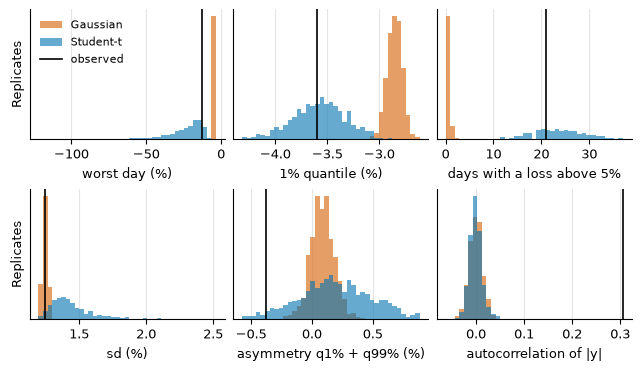

(the Student-t panels show its replicates between their 1% and 99% quantiles)


In [4]:
# Figure: replicated distribution of each statistic for both models, against the observed value
fig, axes = plt.subplots(2, 3, figsize=(6.3, 3.6))
for ax, name in zip(axes.ravel(), observed):
    t_values = replicated["Student-t"][name]
    g_values = replicated["Gaussian"][name]
    low = min(np.quantile(t_values, 0.01), g_values.min(), observed[name])
    high = max(np.quantile(t_values, 0.99), g_values.max(), observed[name])
    bins = np.linspace(low, high, 40)
    ax.hist(g_values, bins=bins, color=COLOR_GAUSS, alpha=0.6, label="Gaussian")
    ax.hist(t_values, bins=bins, color=COLOR_T, alpha=0.6, label="Student-t")
    ax.axvline(observed[name], color="black", linewidth=1.2, label="observed")
    ax.set(xlabel=name, yticks=[])
axes[0, 0].legend(loc="upper left")
axes[0, 0].set_ylabel("Replicates")
axes[1, 0].set_ylabel("Replicates")
save_figure(fig, "ppc.pdf")
plt.show()
print("(the Student-t panels show its replicates between their 1% and 99% quantiles)")

**What we see.**
- **The Gaussian fails every tail statistic.** Its replicates never have a worst day below about −5.4%, against −12.8% observed; they have 0 or 1 day with a loss above 5%, against 21 observed; their 1% quantile is too mild (all p-values 0 or 1).
- **The Student-t reproduces the left tail that matters for VaR and ES:** the 1% quantile ($p = 0.55$) and the number of large losses ($p = 0.68$) are typical of its replicates.
- **But its far tail is too heavy.** The observed worst day sits in the mild part of its replicates ($p = 0.11$), whose worst days reach losses far beyond any day of our window, and its replicated standard deviations are mostly above ours ($p = 0.96$). This confirms the hint of notebooks 04 and 05.
- **Both models miss two features of the data.** The mild asymmetry, losses a little larger than gains ($p = 0.96$ for the Student-t), and above all **volatility clustering**: the autocorrelation of $|y_t|$ is 0.31 in the data and close to 0 in every replicate ($p = 0.00$). Independent days cannot produce calm and turbulent periods.

## 2. VaR exceedances

A 99% VaR should be beaten on about 1% of days. For each model and level, we count the days of our window on which the loss beat the predictive VaR. If the VaR is right, this count is Binomial$(n, 1-\alpha)$, so we give its central 95% range and a two-sided binomial test. This is an in-sample check: the VaR was fitted on these same days.

> **[COURSE]** A count of events as a sum of Bernoulli trials, and its Monte Carlo spread: Ch. 1, Proposition 1.2 (p. 24); Preliminaries, Example 3 (p. 6).

In [5]:
# Exceedances of each model's predictive VaR, against the binomial expectation
losses = -y
var_pred = {}
rows = []
for model, theta, kind in [("Student-t", theta_t, "student_t"), ("Gaussian", theta_g, "gaussian")]:
    for alpha in LEVELS:
        var_pred[(model, alpha)] = predictive_var_es(theta, alpha, kind)[0]
        count = int(np.sum(losses > var_pred[(model, alpha)]))
        low, high = stats.binom.ppf([0.025, 0.975], n, 1 - alpha)
        rows.append({"level": f"{100 * alpha:g}%", "model": model, "exceedances": count,
                     "expected": n * (1 - alpha), "95% range": f"[{low:.0f}, {high:.0f}]",
                     "binomial test p-value": stats.binomtest(count, n, 1 - alpha).pvalue})
exceedances = pd.DataFrame(rows).set_index(["level", "model"])
exceedances.round(3)

,,exceedances,expected,95% range,binomial test p-value
level,model,,,,
97.5%,Student-t,161,125.775,"[105, 148]",0.002
99%,Student-t,51,50.310,"[37, 65]",0.887
99.9%,Student-t,2,5.031,"[1, 10]",0.258
97.5%,Gaussian,156,125.775,"[105, 148]",0.008
99%,Gaussian,105,50.310,"[37, 65]",0.000
99.9%,Gaussian,46,5.031,"[1, 10]",0.000


In [6]:
# Table for the report
report = exceedances.reset_index()
report.index = [f"{level}: {model}" for level, model in zip(report["level"], report["model"])]
report = report[["exceedances", "expected", "95% range", "binomial test p-value"]]
report.columns = ["Exceedances", "Expected", "95% range", "Binomial p-value"]
report["Expected"] = report["Expected"].round(1)
report.index.name = "Level: model"
save_table(report, "exceedances.tex", fmt="{:.3g}")

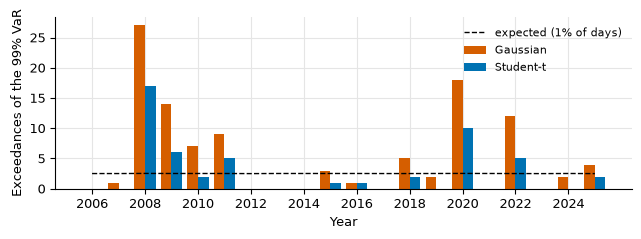

In [7]:
# Figure: exceedances of the 99% VaR, year by year, for both models
years = returns.index.year
counts = pd.DataFrame()
for model in ["Gaussian", "Student-t"]:
    beaten = pd.Series(losses > var_pred[(model, 0.99)], index=returns.index)
    counts[model] = beaten.groupby(years).sum()
fig, ax = plt.subplots(figsize=(6.3, 2.2))
width = 0.4
ax.bar(counts.index - width / 2, counts["Gaussian"], width, color=COLOR_GAUSS, label="Gaussian")
ax.bar(counts.index + width / 2, counts["Student-t"], width, color=COLOR_T, label="Student-t")
days_per_year = pd.Series(1, index=returns.index).groupby(years).sum()
ax.plot(days_per_year.index, 0.01 * days_per_year, "k--", linewidth=1, label="expected (1% of days)")
ax.set(xlabel="Year", ylabel="Exceedances of the 99% VaR", xticks=counts.index[::2])
ax.legend(loc="upper right")
save_figure(fig, "exceedances.pdf")
plt.show()

**What we see.**
- **At 99%, our headline level, the Student-t VaR is right:** it is beaten on 51 days, against 50 expected. The Gaussian VaR is beaten twice as often, and at 99.9% nine times as often.
- **At 99.9%, the Student-t is conservative:** 2 exceedances against 5 expected, inside the binomial range, but in the same direction as the posterior predictive checks.
- **At 97.5%, both models are beaten too often** (161 and 156 against 126). A single Student-t is a compromise over the whole window: too low at 97.5%, right at 99%, too high at 99.9%. This is what a mixture of calm and turbulent periods looks like when it is fitted with one distribution.
- **The exceedances come in clusters** (figure): most of them fall in 2008–2009 and 2020, and many years have none. A VaR for *tomorrow* would need a model whose volatility changes over time.

## 3. Sensitivity to the priors and to the window

Our priors were chosen to be weakly informative. We refit the Student-t model with each prior changed in turn, and once on a shorter, more recent window with the same priors, and report what matters for our question: $\nu$ and the predictive 99% VaR, 99% ES and 99.9% ES. Each refit uses our full recipe, and is checked against the convergence targets.

In [8]:
# The variants: (name, prior setting changed, new value); the window variant refits on 2016-2025
variants = [("nu - 2 ~ Exponential(rate 0.5): heavier tails favoured", "nu_rate", 0.5),
            ("nu - 2 ~ Exponential(rate 0.05): lighter tails favoured", "nu_rate", 0.05),
            ("mu ~ N(0, 0.01^2): the prior of our pitch", "mu_sd", 0.01),
            ("sigma ~ HalfNormal(0.05): a wider prior", "sigma_scale", 0.05),
            ("nu > 1 instead of nu > 2", "nu_min", 1.0)]


def answers(theta):
    """nu (posterior mean and 95% interval) and the predictive 99% VaR, 99% ES and 99.9% ES, in %."""
    var99, es99 = predictive_var_es(theta, 0.99)
    es999 = predictive_var_es(theta, 0.999)[1]
    nu = theta[..., 2]
    return {"nu": nu.mean(), "nu interval": f"[{np.quantile(nu, 0.025):.2f}, {np.quantile(nu, 0.975):.2f}]",
            "VaR 99%": 100 * var99, "ES 99%": 100 * es99, "ES 99.9%": 100 * es999}


def refit(data, prior):
    """Fit the Student-t model to data with the given prior; returns the draws and whether it converged."""
    def target(phi):
        """Log posterior of phi for these data and this prior."""
        return log_posterior(phi, data, prior)

    chains, accept = run_chains(target, [np.median(data), np.log(data.std()), 0.0], rng)
    theta = to_theta(chains[:, BURN_IN:], prior)
    table = pd.DataFrame([summarize(theta[..., i]) for i in range(3)])
    return theta, all(convergence_checks(table, accept).values())


rows = {"baseline (notebook 04)": answers(theta_t)}
rows["baseline (notebook 04)"]["converged"] = True
for name, key, value in variants:
    prior = dict(PRIOR)  # a copy of our priors, with one setting changed
    prior[key] = value
    theta, converged = refit(y, prior)
    rows[name] = answers(theta)
    rows[name]["converged"] = converged
theta, converged = refit(returns["2016-01-01":].to_numpy(), PRIOR)
rows["window 2016-2025 (10 years), same priors"] = answers(theta)
rows["window 2016-2025 (10 years), same priors"]["converged"] = converged

sensitivity = pd.DataFrame.from_dict(rows, orient="index")
baseline = sensitivity.loc["baseline (notebook 04)"]
for column in ["VaR 99%", "ES 99%", "ES 99.9%"]:
    sensitivity[f"{column}: change (%)"] = 100 * (sensitivity[column] / baseline[column] - 1)
sensitivity.round(2)

,nu,nu interval,VaR 99%,ES 99%,ES 99.9%,converged,VaR 99%: change (%),ES 99%: change (%),ES 99.9%: change (%)
baseline (notebook 04),2.48,"[2.27, 2.70]",3.60,6.24,16.24,True,0.00,0.00,0.00
nu - 2 ~ Exponential(rate 0.5): heavier tails favoured,2.48,"[2.27, 2.70]",3.60,6.25,16.29,True,0.07,0.17,0.31
nu - 2 ~ Exponential(rate 0.05): lighter tails favoured,2.48,"[2.28, 2.71]",3.60,6.23,16.22,True,-0.06,-0.09,-0.13
"mu ~ N(0, 0.01^2): the prior of our pitch",2.48,"[2.27, 2.70]",3.59,6.22,16.18,True,-0.19,-0.25,-0.35
sigma ~ HalfNormal(0.05): a wider prior,2.48,"[2.28, 2.70]",3.60,6.24,16.24,True,-0.02,-0.02,-0.01
nu > 1 instead of nu > 2,2.48,"[2.28, 2.70]",3.60,6.24,16.27,True,0.05,0.10,0.17
"window 2016-2025 (10 years), same priors",2.68,"[2.36, 3.05]",3.25,5.41,13.32,True,-9.59,-13.19,-17.96


In [9]:
# Table for the report, and the largest change due to the priors alone
report = pd.DataFrame({
    r"$\nu$": [f"{v:.2f} {i}" for v, i in zip(sensitivity["nu"], sensitivity["nu interval"])],
    "VaR 99%": [f"{v:.2f}" for v in sensitivity["VaR 99%"]],
    "ES 99%": [f"{v:.2f}" for v in sensitivity["ES 99%"]],
    "ES 99.9%": [f"{v:.2f}" for v in sensitivity["ES 99.9%"]]},
    index=["Baseline", r"$\nu - 2 \sim$ Exponential(rate 0.5)", r"$\nu - 2 \sim$ Exponential(rate 0.05)",
           r"$\mu \sim \mathcal{N}(0, 0.01^2)$ (pitch)", r"$\sigma \sim$ HalfNormal(0.05)",
           r"$\nu > 1$ instead of $\nu > 2$", "Window 2016--2025, same priors"])
report.index.name = "Variant (losses in %)"
save_table(report, "sensitivity.tex")

prior_rows = sensitivity.index[1:-1]
changes = sensitivity.loc[prior_rows, ["VaR 99%: change (%)", "ES 99%: change (%)", "ES 99.9%: change (%)"]]
print(f"all refits converged: {sensitivity['converged'].all()}")
print(f"largest change due to the priors: {changes.abs().max().max():.1f}%")

all refits converged: True
largest change due to the priors: 0.3%


**What we see.** All seven refits converged. **The priors do not matter:** changing any of them moves $\nu$ by less than 0.01 and the VaR and ES by at most 0.3%, because 5,031 days dominate weakly informative priors. **The window matters more:** on 2016–2025 only, $\nu$ rises to 2.68 (still very heavy tails) and the 99% VaR falls by about 10%, the 99.9% ES by about 18%, since the most recent decade misses the 2008 crisis. Our answer describes the 2006–2025 window, crises included, and the choice of window should be stated with it.

## 4. Cross-check by importance sampling

Finally, we compute the same posterior with an algorithm of Chapter 3 that shares nothing with our random walk: **self-normalized importance sampling**. We draw $\phi^{(1)}, \dots, \phi^{(M)}$ from a proposal $g$, a multivariate Student-t with 4 degrees of freedom centred at the MAP with the Laplace covariance (heavier tails than the posterior, so the weights stay bounded), and weight each draw by $\bar w_i \propto \tilde\pi(\phi^{(i)} \mid y)/g(\phi^{(i)})$, computed on the log scale and normalized with the log-sum-exp trick. The effective sample size $1/\sum_i \bar w_i^2$ and the largest weights tell us whether the proposal is good, without knowing the answer.

> **[COURSE]** Self-normalized importance sampling and its ESS: Ch. 3, Sec. 3.4.2, Definition 3.3 (p. 45); a Laplace proposal with Student-t tails: Example 3.4 (p. 45); log-sum-exp: Ch. 1, Remark 1.3 (p. 20). Two different algorithms that agree: Ch. 6, Example 6.2 (p. 69).

In [10]:
# Proposal: Student-t with IS_DF degrees of freedom at the MAP, with the Laplace covariance
def target(phi):
    """Log posterior of the Student-t model given the real returns."""
    return log_posterior(phi, y)

mode, laplace = find_map(target, [np.median(y), np.log(y.std()), 0.0])
g = stats.multivariate_t(loc=mode, shape=laplace, df=IS_DF)
phi_is = g.rvs(size=N_IS, random_state=rng)

# Normalized importance weights, on the log scale
log_w = np.array([target(phi) for phi in phi_is]) - g.logpdf(phi_is)
w_bar = np.exp(log_w - logsumexp(log_w))
theta_is = to_theta(phi_is)
print(f"ESS of the weights: {1 / np.sum(w_bar**2):,.0f} of {N_IS:,} "
      f"({100 / np.sum(w_bar**2) / N_IS:.0f}%)")
print(f"largest normalized weights: {np.sort(w_bar)[-3:][::-1].round(6)} (equal weights: {1 / N_IS:.6f})")

ESS of the weights: 41,034 of 50,000 (82%)
largest normalized weights: [7.8e-05 7.8e-05 7.7e-05] (equal weights: 0.000020)


In [11]:
def weighted_quantile(x, weights, q):
    """Quantile q of a sample x with normalized weights."""
    order = np.argsort(x)
    cumulative = np.cumsum(weights[order])
    return np.interp(q, cumulative, x[order])


# Posterior means, 95% intervals and predictive risk measures: random walk MH against importance sampling
rows = {}
for i, (name, scale) in enumerate([("mu (%)", 100), ("sigma (%)", 100), ("nu", 1)]):
    mh = scale * theta_t[..., i].ravel()
    x = scale * theta_is[:, i]
    rows[name] = {"MH": mh.mean(), "importance sampling": np.sum(w_bar * x),
                  "MH 95% interval": f"[{np.quantile(mh, 0.025):.3f}, {np.quantile(mh, 0.975):.3f}]",
                  "IS 95% interval": (f"[{weighted_quantile(x, w_bar, 0.025):.3f}, "
                                      f"{weighted_quantile(x, w_bar, 0.975):.3f}]")}
for alpha in [0.99, 0.999]:
    var_mh, es_mh = predictive_var_es(theta_t, alpha)
    var_is, es_is = predictive_var_es(theta_is, alpha, weights=w_bar)
    rows[f"VaR {100 * alpha:g}% (%)"] = {"MH": 100 * var_mh, "importance sampling": 100 * var_is}
    rows[f"ES {100 * alpha:g}% (%)"] = {"MH": 100 * es_mh, "importance sampling": 100 * es_is}
crosscheck = pd.DataFrame.from_dict(rows, orient="index")
crosscheck["difference (%)"] = 100 * (crosscheck["importance sampling"] / crosscheck["MH"] - 1)
crosscheck.index.name = "Quantity"

# Table for the report, written as text (the risk measures have no interval here)
report = pd.DataFrame({
    "MH": [f"{v:.3f}" for v in crosscheck["MH"]],
    "Importance sampling": [f"{v:.3f}" for v in crosscheck["importance sampling"]],
    "Difference (%)": [f"{v:+.2f}" for v in crosscheck["difference (%)"]],
    "MH 95% interval": [str(v) if isinstance(v, str) else "" for v in crosscheck["MH 95% interval"]],
    "IS 95% interval": [str(v) if isinstance(v, str) else "" for v in crosscheck["IS 95% interval"]]},
    index=[r"$\mu$ (%)", r"$\sigma$ (%)", r"$\nu$"] + list(crosscheck.index[3:]))
save_table(report, "crosscheck.tex")
crosscheck.round(3)

,MH,importance sampling,MH 95% interval,IS 95% interval,difference (%)
Quantity,,,,,
mu (%),0.096,0.097,"[0.073, 0.120]","[0.073, 0.120]",0.108
sigma (%),0.683,0.683,"[0.656, 0.711]","[0.656, 0.711]",-0.026
nu,2.481,2.481,"[2.274, 2.704]","[2.276, 2.706]",0.030
VaR 99% (%),3.599,3.597,NaN,NaN,-0.065
ES 99% (%),6.238,6.232,NaN,NaN,-0.091
VaR 99.9% (%),9.556,9.547,NaN,NaN,-0.097
ES 99.9% (%),16.240,16.219,NaN,NaN,-0.130


**What we see.** Importance sampling is efficient here (82% of its draws are effective, and no weight dominates: the largest is about four times an equal weight), and it reaches the same posterior as our random walk: the means, the 95% intervals and the predictive VaR and ES all agree within 0.13%. With the independence sampler of notebook 04, three algorithms that move in different ways reach the same posterior.

## 5. What we found

In [12]:
# Numbers quoted in the report
for name in observed:
    print(f"{name:>28}: observed {observed[name]:.3g}; "
          f"p-value Student-t {ppc.loc[name, 'Student-t: p-value']:.2f}, "
          f"Gaussian {ppc.loc[name, 'Gaussian: p-value']:.2f}")
for (level, model), r in exceedances.iterrows():
    print(f"exceedances {level:>6} {model:>9}: {r['exceedances']:4d} against {r['expected']:6.1f} expected "
          f"{r['95% range']}, p = {r['binomial test p-value']:.3f}")
print(f"sensitivity: largest change due to the priors {changes.abs().max().max():.1f}%; window 2016-2025: "
      f"nu {sensitivity.iloc[-1]['nu']:.2f}, VaR 99% {sensitivity.iloc[-1]['VaR 99%']:.2f}%, "
      f"ES 99% {sensitivity.iloc[-1]['ES 99%']:.2f}%, ES 99.9% {sensitivity.iloc[-1]['ES 99.9%']:.2f}%")
print(f"cross-check: ESS {1 / np.sum(w_bar**2):,.0f} of {N_IS:,}; "
      f"largest difference with MH {crosscheck['difference (%)'].abs().max():.2f}%")

               worst day (%): observed -12.8; p-value Student-t 0.11, Gaussian 1.00
             1% quantile (%): observed -3.6; p-value Student-t 0.55, Gaussian 1.00
   days with a loss above 5%: observed 21; p-value Student-t 0.68, Gaussian 0.00
                      sd (%): observed 1.25; p-value Student-t 0.96, Gaussian 0.51
    asymmetry q1% + q99% (%): observed -0.375; p-value Student-t 0.96, Gaussian 1.00
      autocorrelation of |y|: observed 0.305; p-value Student-t 0.00, Gaussian 0.00
exceedances  97.5% Student-t:  161 against  125.8 expected [105, 148], p = 0.002
exceedances    99% Student-t:   51 against   50.3 expected [37, 65], p = 0.887
exceedances  99.9% Student-t:    2 against    5.0 expected [1, 10], p = 0.258
exceedances  97.5%  Gaussian:  156 against  125.8 expected [105, 148], p = 0.008
exceedances    99%  Gaussian:  105 against   50.3 expected [37, 65], p = 0.000
exceedances  99.9%  Gaussian:   46 against    5.0 expected [1, 10], p = 0.000
sensitivity: largest cha

- **The Student-t model fits what our question needs:** it reproduces the 1% quantile and the number of large losses, and its 99% VaR is beaten on 51 days against 50 expected. The Gaussian fails every tail check, and its 99% VaR is beaten twice as often as it should be.
- **Its limitations are clear.** It misses volatility clustering (exceedances bunch in 2008 and 2020) and the mild asymmetry. Pooled over calm and crisis periods, a single tail parameter is a compromise: too low at 97.5%, right at 99%, too heavy at 99.9%, so the model is conservative for the most extreme losses.
- **The answer is robust to the priors** (changes of at most 0.3%), less so to the window (the 99% VaR falls by about 10% on 2016–2025).
- **The posterior is the same with a Chapter 3 method:** importance sampling agrees with our sampler within 0.13%.

**What would come next:** a model whose volatility changes over time, such as a GARCH model with Student-t errors, for a VaR conditional on today's market; a skewed distribution for the asymmetry; and an out-of-sample backtest.